In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
singlecol = 3.5
plt.rcParams.update({'font.size': 8})
#plt.rcParams.update({'font.sans-serif': 'Helvetica'})
plt.rcParams.update({'lines.linewidth':1.5})
plt.rcParams.update({'axes.linewidth':1})
plt.rcParams.update({'lines.markersize':5})
plt.rcParams.update({'savefig.dpi':200})
plt.rcParams.update({'legend.fontsize': 8})

In [2]:
def extract_info(report_file, timestep_file):
    # Extract info from report file
    with open(report_file, 'r') as f:
        content = f.read()
        num_configs = re.search(r'Errors checked for (\d+) configurations', content).group(1)
        energy_per_atom_rms = re.search(r'Energy per atom:.*?RMS\s+absolute difference = (\d+\.\d+)', content, re.DOTALL).group(1)
        forces_rms = re.search(r'Forces:.*?RMS\s+absolute difference = (\d+\.\d+)', content, re.DOTALL).group(1)
        stress_rms = re.search(r'Stresses:.*?RMS\s+absolute difference = (\d+\.\d+)', content, re.DOTALL).group(1)
    
    # Extract timesteps
    #with open(timestep_file, 'r') as f:
     #   timesteps = f.read().strip().split(' ')
    
    return num_configs, energy_per_atom_rms, forces_rms, stress_rms#, timesteps

def natural_sort_key(s):
    return [int(c) if c.isdigit() else c.lower() for c in re.split(r'(\d+)', s)]

In [3]:
import re

def extract_info(report_file):
    # Extract info from report file
    with open(report_file, 'r') as f:
        content = f.read()
    
    def extract_value(pattern, text, default="N/A"):
        """Utility to extract a value using regex with a default fallback."""
        match = re.search(pattern, text, re.DOTALL)
        return match.group(1) if match else default

    num_configs = extract_value(r'Errors checked for (\d+) configurations', content)
    energy_per_atom_rms = extract_value(r'Energy per atom:.*?RMS\s+absolute difference = (\d+\.\d+)', content)
    forces_rms = extract_value(r'Forces:.*?RMS\s+absolute difference = (\d+\.\d+)', content)
    stress_rms = extract_value(r'Stresses.*?RMS\s+absolute difference = (\d+\.\d+)', content)
    
    # Extract timesteps
    #with open(timestep_file, 'r') as f:
    #    timesteps = f.read().strip().split(' ')
    
    return num_configs, energy_per_atom_rms, forces_rms, stress_rms#, timesteps

def natural_sort_key(s):
    return [int(c) if c.isdigit() else c.lower() for c in re.split(r'(\d+)', s)]


In [4]:
report_files = sorted([f for f in os.listdir('./pot_save/') if f.startswith('report_') and f.endswith('.txt')], key=natural_sort_key)
timestep_files = sorted([f for f in os.listdir('./pot_save/') if f.startswith('timestep') and f.endswith('.txt')], key=natural_sort_key)

## Monitor

In [8]:
start=275
iteration=293
# Create status.txt
with open('status.txt', 'w') as status_file:
    status_file.write("Iteration, Train set size, RMS(E/atom), RMS(f) , RMS(S)\n")#, timestep 1, timestep 2, timestep 3, timestep 4\n")
    
    for i in range(start,iteration):#len(timestep_files)-1):
        print(i)
        num_configs, energy_per_atom_rms, forces_rms, stress_rms = extract_info(f'./pot_save/report_{i+1}.txt')
        status_file.write(f"{i+1}, {num_configs}, {energy_per_atom_rms}, {forces_rms}, {stress_rms}\n")#, {timesteps[4]}, {timesteps[5]}, {timesteps[6]}, {timesteps[7]}\n")

print("status.txt has been created successfully.")


275
276
277
278
279
280
281
282
283
284
285
286
287
288
289
290
291
292
status.txt has been created successfully.


In [9]:
df = pd.read_csv('status.txt', header=None, names=['Iteration', 'Train set size', 'RMS(E/atom)', 'RMS(f)', 'RMS(S)', 'Timestep1', 'Timestep2', 'Timestep3', 'Timestep4', 'Timestep5', 'Timestep6', 'Timestep7', 'Timestep8'])
numeric_columns = ['Iteration', 'Train set size', 'RMS(E/atom)', 'RMS(f)', 'RMS(S)', 'Timestep1', 'Timestep2', 'Timestep3', 'Timestep4', 'Timestep5', 'Timestep6', 'Timestep7', 'Timestep8']
df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors='coerce')

(275.0, 293.0)

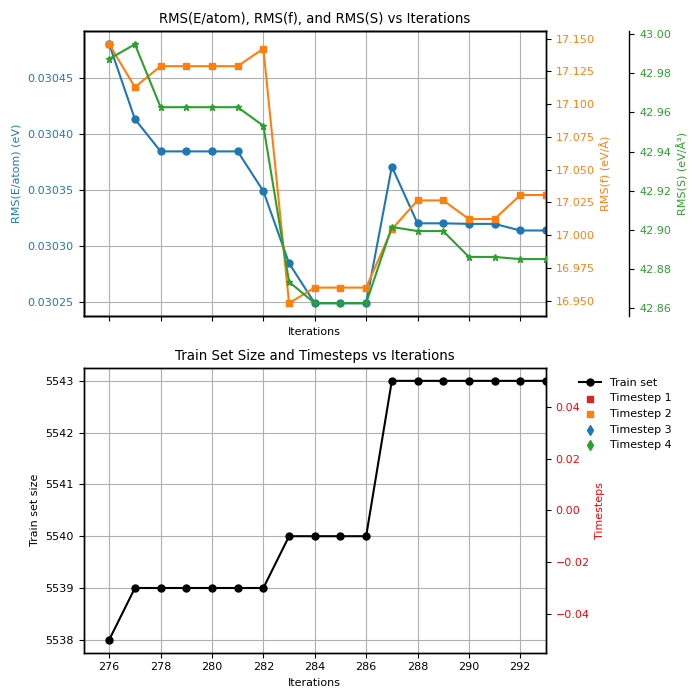

In [10]:
%matplotlib widget
iterations = df['Iteration']
train_set_sizes = df['Train set size']
rms_e_atom = df['RMS(E/atom)']
rms_f = df['RMS(f)']
rms_S = df['RMS(S)']
timestep1 = df['Timestep1']
timestep2 = df['Timestep2']
timestep3 = df['Timestep3']
timestep4 = df['Timestep4']
#timestep5 = df['Timestep5']
#timestep6 = df['Timestep6']

# Create the figure with two subplots
fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(singlecol*2, singlecol*2), sharex=True)

# Top subplot: RMS(E/atom) and RMS(f) vs Iterations
color1 = 'tab:blue'
ax1.set_xlabel('Iterations')
ax1.set_ylabel('RMS(E/atom) (eV)', color=color1)
ax1.plot(iterations, rms_e_atom, color=color1, marker='o', label='RMS(E/atom)')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid()

ax2 = ax1.twinx()
color2 = 'tab:orange'
ax2.set_ylabel('RMS(f) (eV/Å)', color=color2)
ax2.plot(iterations, rms_f, color=color2, marker='s', label='RMS(f)')
ax2.tick_params(axis='y', labelcolor=color2)

ax22 = ax1.twinx()
color = 'tab:green'
ax22.spines['right'].set_position(('outward', 60)) 
ax22.set_ylabel('RMS(S) (eV/Å³)', color=color)
ax22.plot(iterations, rms_S, color=color, marker='*')
ax22.tick_params(axis='y', labelcolor=color)

ax1.set_title('RMS(E/atom), RMS(f), and RMS(S) vs Iterations')
#lines1, labels1 = ax1.get_legend_handles_labels()
#lines2, labels2 = ax2.get_legend_handles_labels()
#lines3, labels3 = ax22.get_legend_handles_labels()
#ax1.legend(lines1 + lines2, labels1 + labels2,  labels1 + labels2,frameon=False,bbox_to_anchor=(1.05, 1), loc='upper left')

# Bottom subplot: Train Set Size and Timesteps vs Iterations
color3 = 'black'
ax3.set_xlabel('Iterations')
ax3.set_ylabel('Train set size', color=color3)
ax3.plot(iterations, train_set_sizes, color=color3, marker='o', label='Train set')
#ax3.plot(range(1,data.shape[0]), row_sums[1:], marker='d', markersize= 3, color='black', label='Active set')
ax3.tick_params(axis='y', labelcolor=color3)
ax3.grid()

ax4 = ax3.twinx()
ax4.set_ylabel('Timesteps', color='red')
ax4.scatter(iterations, timestep1, color='tab:red', marker='s', label='Timestep 1')
ax4.scatter(iterations, timestep2, color='tab:orange', marker='s', label='Timestep 2')
ax4.scatter(iterations, timestep3, color='tab:blue', marker='d', label='Timestep 3')
ax4.scatter(iterations, timestep4, color='tab:green', marker='d', label='Timestep 4')
#ax4.scatter(iterations, timestep5, color='tab:purple', marker='s', label='Timestep 5')
#ax4.scatter(iterations, timestep6, color='tab:cyan', marker='d', label='Timestep 6')
ax4.tick_params(axis='y', labelcolor='red')

ax3.set_title('Train Set Size and Timesteps vs Iterations')
lines3, labels3 = ax3.get_legend_handles_labels()
lines4, labels4 = ax4.get_legend_handles_labels()
ax3.legend(lines3 + lines4, labels3 + labels4, frameon=False,bbox_to_anchor=(1.05, 1), loc='upper left')

# Adjust layout
plt.tight_layout()
plt.xlim(start,iteration)
#plt.xlim(iteration-50,iteration)
# Alternatively, save the plot
#plt.savefig('monitoring.png', dpi=300, bbox_inches='tight')

In [9]:
rms_e_atom.iloc[-1], rms_f.iloc[-1], rms_S.iloc[-1]

(0.0230047, 0.985764, 34.2858)

In [10]:
train_set_sizes

0        NaN
1     3336.0
2     3354.0
3     3372.0
4     3390.0
       ...  
68    3552.0
69    3552.0
70    3552.0
71    3552.0
72    3552.0
Name: Train set size, Length: 73, dtype: float64

In [5]:
import os

output_file = "active_set.txt"
temp_files = []

# Track all unique atom counts across all files
all_atom_counts = set()

for i in range(start+1,iteration + 1):
    input_file = f"curr_{i}.almtp"
    temp_file = f"temp_{i}.txt"
    
    if os.path.isfile(input_file):
        atom_count = {}
        
        try:
            with open(input_file, 'r', encoding='utf-8', errors='ignore') as infile:
                lines = infile.readlines()
            
            for j in range(len(lines)):
                if 'Size' in lines[j]:
                    if j + 1 < len(lines):
                        size = lines[j + 1].strip().split()[0]
                        if size in atom_count:
                            atom_count[size] += 1
                        else:
                            atom_count[size] = 1
                        # Add to all_atom_counts set
                        all_atom_counts.add(size)
            
            with open(temp_file, 'w', encoding='utf-8') as outfile:
                for count in sorted(atom_count.keys(), key=int):
                    outfile.write(f"{count} {atom_count[count]}\n")
            
            temp_files.append(temp_file)
        except Exception as e:
            print(f"Error processing file {input_file}: {e}")
    else:
        print(f"File: {input_file} does not exist.")

# Sort all unique atom counts
all_atom_counts = sorted(all_atom_counts, key=int)

# Create a mapping from atom count to index
atom_count_index = {str(count): idx for idx, count in enumerate(all_atom_counts)}

# Prepare an empty data structure to hold counts for each file
file_atom_counts = [[0] * len(all_atom_counts) for _ in range(iteration + 1)]

# Read the temporary files and populate file_atom_counts
for file_idx, temp_file in enumerate(temp_files):
    with open(temp_file, 'r', encoding='utf-8') as infile:
        lines = infile.readlines()
        for line in lines:
            count, num_configurations = line.strip().split()
            idx = atom_count_index[count]
            file_atom_counts[file_idx][idx] = num_configurations

# Write the final output file
with open(output_file, 'w', encoding='utf-8') as outfile:
    # Write the header row
    outfile.write("\t".join(map(str, all_atom_counts)) + "\n")
    
    # Write the counts for each iteration
    for counts in file_atom_counts:
        outfile.write("\t".join(map(str, counts)) + "\n")

# Clean up temporary files
for temp_file in temp_files:
    os.remove(temp_file)


In [ ]:
data = np.loadtxt('active_set.txt')
row_sums = np.sum(data, axis=1)
atom_num = all_atom_counts

### Active set analysis

(390.0, 435.0)

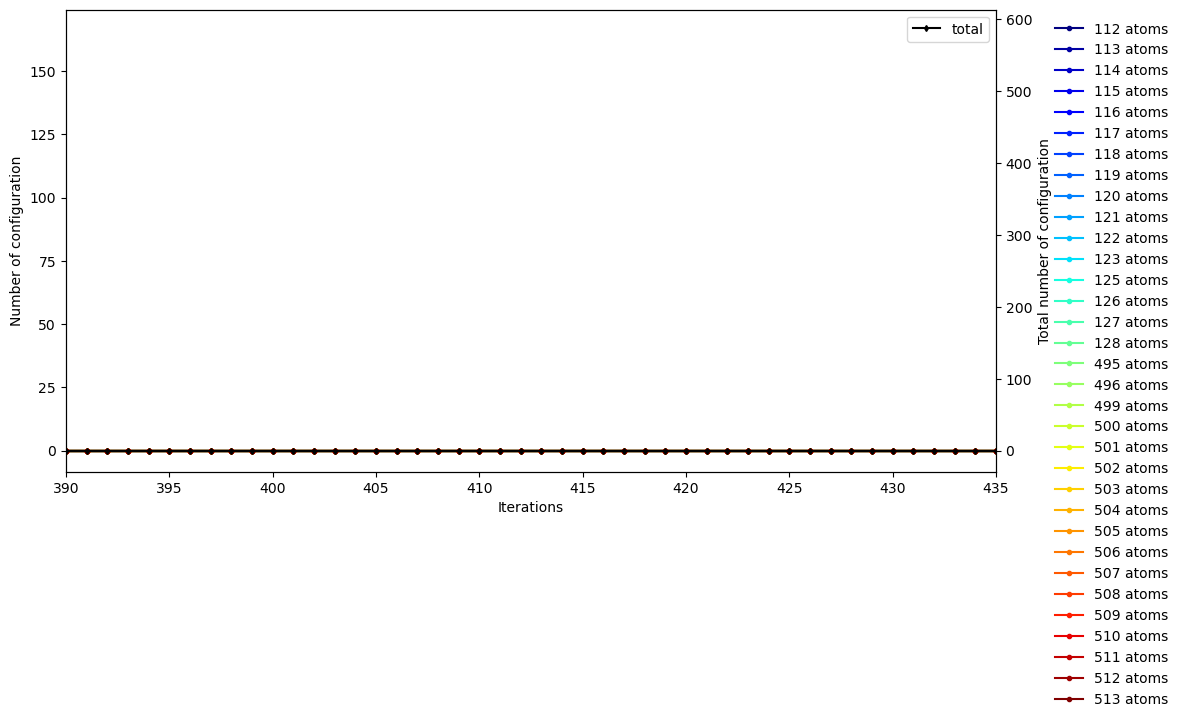

In [8]:
fig, ax1 = plt.subplots(figsize=(12, 6))
colors = cm.jet(np.linspace(0, 1, data.shape[1]))
ax2=ax1.twinx()
for i in range(data.shape[1]):
    ax1.plot(range(1,data.shape[0]), data[1:,i], marker='o', markersize= 3, label=f'{atom_num[i]} atoms', color=colors[i])
ax2.plot(range(1,data.shape[0]), row_sums[1:], marker='d', markersize= 3, color='black', label='total')
        
ax1.set_xlabel('Iterations')
ax1.set_ylabel('Number of configuration')
ax2.set_ylabel('Total number of configuration')
ax1.legend(frameon=False,bbox_to_anchor=(1.05, 1), loc='upper left')
ax2.legend()
plt.xlim(start,iteration)
#plt.savefig('active set.png', dpi=300, bbox_inches='tight')

In [ ]:
# Create the figure and the first y-axis
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Iterations')
ax1.set_ylabel('RMS E/atom (eV)', color=color)
ax1.plot(iterations, rms_e_atom, color=color, marker='o')
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('RMS f (eV/Å)', color=color)
ax2.plot(iterations, rms_f, color=color, marker='s')
ax2.tick_params(axis='y', labelcolor=color)

# Add a title
plt.title('RMS(E/atom) and RMS(f) vs Iterations')

# Add a legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, ['RMS(E/atom)', 'RMS(f)'], loc='upper right')

# Adjust layout and display the plot
fig.tight_layout()
plt.show()

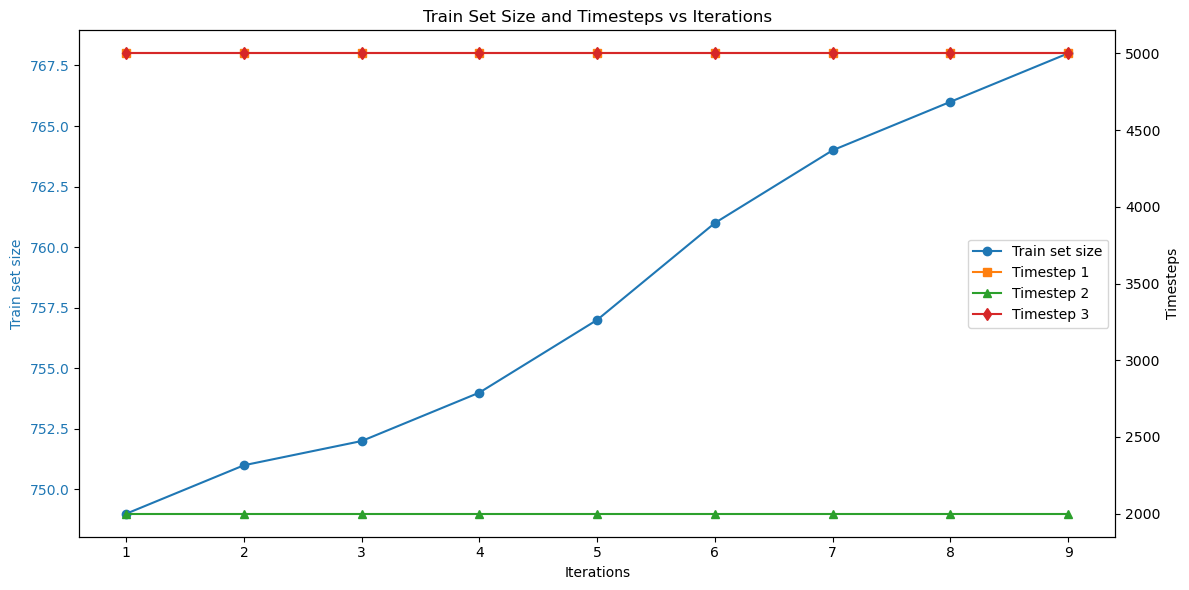

In [45]:
# Create the figure and the first y-axis
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot train_set_sizes on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Iterations')
ax1.set_ylabel('Train set size', color=color)
ax1.plot(iterations, train_set_sizes, color=color, marker='o', label='Train set size')
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot timesteps
ax2 = ax1.twinx()
color1 = 'tab:orange'
color2 = 'tab:green'
color3 = 'tab:red'
ax2.set_ylabel('Timesteps')
ax2.plot(iterations, timestep1, color=color1, marker='s', label='Timestep 1')
ax2.plot(iterations, timestep2, color=color2, marker='^', label='Timestep 2')
ax2.plot(iterations, timestep3, color=color3, marker='d', label='Timestep 3')
ax2.tick_params(axis='y')

# Add a title
plt.title('Train Set Size and Timesteps vs Iterations')

# Add legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='center right')

# Adjust layout and display the plot
fig.tight_layout()
plt.show()

## Present

In [26]:
start=450
iteration=503
# Create status.txt
with open('status.txt', 'w') as status_file:
    status_file.write("Iteration, Train set size, RMS(E/atom), RMS(f) , RMS(S), timestep 16\n")
    
    for i in range(start,iteration):#len(timestep_files)-1):
        num_configs, energy_per_atom_rms, forces_rms, stress_rms, timesteps = extract_info(f'report_{i+1}.txt',f'timestep{i+1}.txt')
        status_file.write(f"{i+1}, {num_configs}, {energy_per_atom_rms}, {forces_rms}, {stress_rms}, {timesteps[0]}\n")# {timesteps[1]}, {timesteps[2]}\n")

print("status.txt has been created successfully.")


status.txt has been created successfully.


In [27]:
df = pd.read_csv('status.txt', header=None, names=['Iteration', 'Train set size', 'RMS(E/atom)', 'RMS(f)', 'RMS(S)', 'Timestep1'])
numeric_columns = ['Iteration', 'Train set size', 'RMS(E/atom)', 'RMS(f)', 'RMS(S)', 'Timestep1']
df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors='coerce')

(350.0, 498.0)

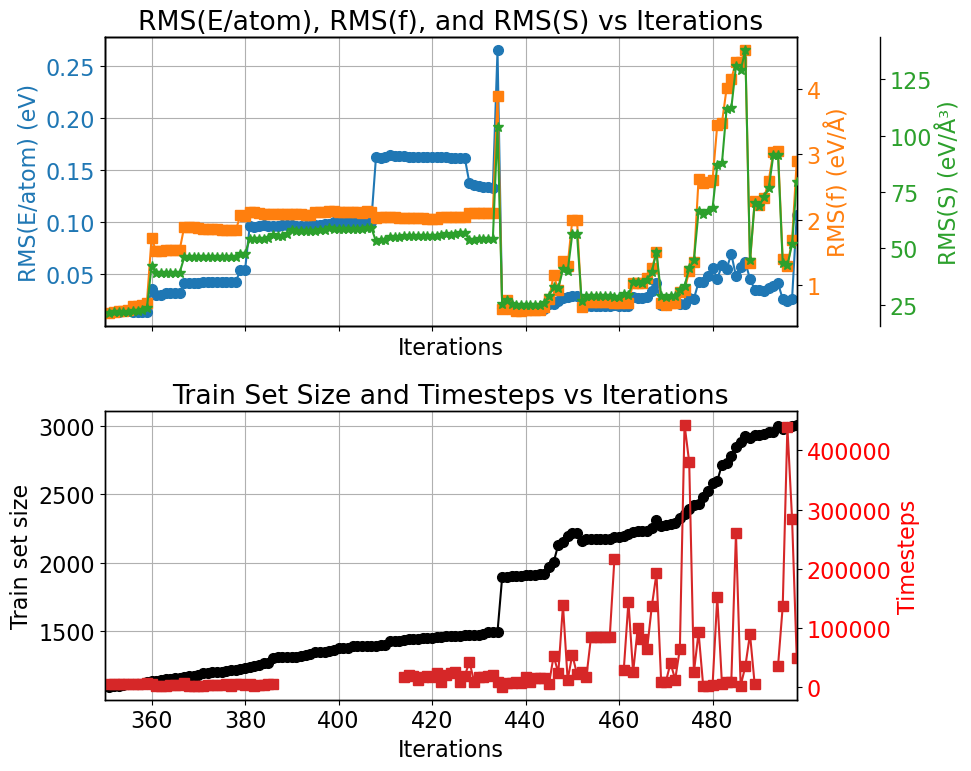

In [28]:
iterations = df['Iteration']
train_set_sizes = df['Train set size']
rms_e_atom = df['RMS(E/atom)']
rms_f = df['RMS(f)']
rms_S = df['RMS(S)']
timestep1 = df['Timestep1']

# Create the figure with two subplots
fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(10,8), sharex=True)

# Top subplot: RMS(E/atom) and RMS(f) vs Iterations
color1 = 'tab:blue'
ax1.set_xlabel('Iterations')
ax1.set_ylabel('RMS(E/atom) (eV)', color=color1)
ax1.plot(iterations, rms_e_atom, color=color1, marker='o', label='RMS(E/atom)')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid()

ax2 = ax1.twinx()
color2 = 'tab:orange'
ax2.set_ylabel('RMS(f) (eV/Å)', color=color2)
ax2.plot(iterations, rms_f, color=color2, marker='s', label='RMS(f)')
ax2.tick_params(axis='y', labelcolor=color2)

ax22 = ax1.twinx()
color = 'tab:green'
ax22.spines['right'].set_position(('outward', 60)) 
ax22.set_ylabel('RMS(S) (eV/Å³)', color=color)
ax22.plot(iterations, rms_S, color=color, marker='*')
ax22.tick_params(axis='y', labelcolor=color)

ax1.set_title('RMS(E/atom), RMS(f), and RMS(S) vs Iterations')

# Bottom subplot: Train Set Size and Timesteps vs Iterations
color3 = 'black'
ax3.set_xlabel('Iterations')
ax3.set_ylabel('Train set size', color=color3)
ax3.plot(iterations, train_set_sizes, color=color3, marker='o', label='Train set')
#ax3.plot(range(1,data.shape[0]), row_sums[1:], marker='d', markersize= 3, color='black', label='Active set')
ax3.tick_params(axis='y', labelcolor=color3)
ax3.grid()

ax4 = ax3.twinx()
ax4.set_ylabel('Timesteps', color='red')
ax4.plot(iterations, timestep1, color='tab:red', marker='s', label='Timestep 1')
ax4.tick_params(axis='y', labelcolor='red')

ax3.set_title('Train Set Size and Timesteps vs Iterations')
lines3, labels3 = ax3.get_legend_handles_labels()
lines4, labels4 = ax4.get_legend_handles_labels()
#ax3.legend(lines3 + lines4, labels3 + labels4, frameon=False,bbox_to_anchor=(1.05, 1), loc='upper left')

# Adjust layout
plt.tight_layout()
plt.xlim(start,iteration)
#plt.xlim(iteration-50,iteration)
# Alternatively, save the plot
#plt.savefig('monitoring.png', dpi=300, bbox_inches='tight')